# 🧠 Convolutional Neural Network 실습 (TensorFlow/Keras + MNIST)

이 노트북에서는 Convolution과 Pooling의 개념을 실습합니다.

## 주요 포인트
- Convolution: kernel size, padding, stride, dilation, filter 개수, bias
- Pooling: MaxPooling vs AveragePooling


In [1]:
import tensorflow as tf
from tensorflow.keras import layers, models
import numpy as np
import matplotlib.pyplot as plt

print('TensorFlow version:', tf.__version__)

TensorFlow version: 2.21.0


## [1] MNIST 데이터 로드 및 전처리

Train shape: (60000, 28, 28, 1)
Test shape: (10000, 28, 28, 1)


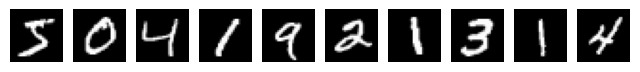

In [2]:
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()
x_train = x_train.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0
x_train = np.expand_dims(x_train, -1)
x_test = np.expand_dims(x_test, -1)

print('Train shape:', x_train.shape)
print('Test shape:', x_test.shape)

plt.figure(figsize=(8, 2))
for i in range(10):
    plt.subplot(1, 10, i+1)
    plt.imshow(x_train[i].squeeze(), cmap='gray')
    plt.axis('off')
plt.show()

## [2] Convolution 실습
### 2.1 Kernel size & Padding

In [3]:
sample = x_train[0:1]

conv_valid = layers.Conv2D(filters=1, kernel_size=(3,3), padding='valid', use_bias=False)
conv_same = layers.Conv2D(filters=1, kernel_size=(3,3), padding='same', use_bias=False)

out_valid = conv_valid(sample)
out_same = conv_same(sample)

print('입력:', sample.shape)
print('valid 출력:', out_valid.shape)
print('same 출력:', out_same.shape)

입력: (1, 28, 28, 1)
valid 출력: (1, 26, 26, 1)
same 출력: (1, 28, 28, 1)


### 2.2 Stride와 Dilation

In [4]:
conv_stride = layers.Conv2D(1, (3,3), strides=(2,2), padding='same', use_bias=False)
conv_dilated = layers.Conv2D(1, (3,3), dilation_rate=(2,2), padding='same', use_bias=False)

out_stride = conv_stride(sample)
out_dilated = conv_dilated(sample)

print('stride=2 출력:', out_stride.shape)
print('dilation=2 출력:', out_dilated.shape)

stride=2 출력: (1, 14, 14, 1)
dilation=2 출력: (1, 28, 28, 1)


### 2.3 Filter 개수

출력 shape: (1, 28, 28, 8)


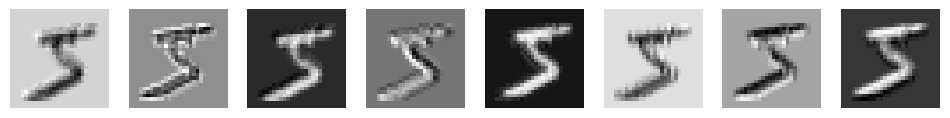

In [5]:
conv_multi = layers.Conv2D(8, (3,3), padding='same', use_bias=False)
out_multi = conv_multi(sample)
print('출력 shape:', out_multi.shape)

fig, axes = plt.subplots(1, 8, figsize=(12, 2))
for i in range(8):
    axes[i].imshow(out_multi[0, :, :, i], cmap='gray')
    axes[i].axis('off')
plt.show()

## [3] Pooling 실습

입력: (1, 28, 28, 1)
Max Pool 출력: (1, 14, 14, 1)
Avg Pool 출력: (1, 14, 14, 1)


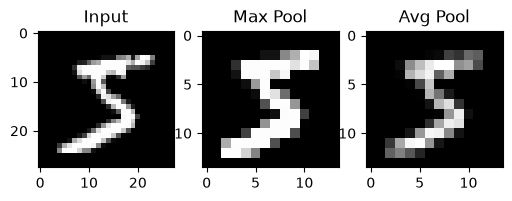

In [6]:
pool_max = layers.MaxPooling2D(pool_size=(2,2), strides=2)
pool_avg = layers.AveragePooling2D(pool_size=(2,2), strides=2)

out_max = pool_max(sample)
out_avg = pool_avg(sample)

print('입력:', sample.shape)
print('Max Pool 출력:', out_max.shape)
print('Avg Pool 출력:', out_avg.shape)

plt.figure(figsize=(6,2))
plt.subplot(1,3,1)
plt.title('Input')
plt.imshow(sample[0].squeeze(), cmap='gray')

plt.subplot(1,3,2)
plt.title('Max Pool')
plt.imshow(out_max[0], cmap='gray')

plt.subplot(1,3,3)
plt.title('Avg Pool')
plt.imshow(out_avg[0], cmap='gray')
plt.show()

## [4] CNN 간단 학습 실습

In [7]:
model = models.Sequential([
    layers.Conv2D(32, (3,3), activation='relu', input_shape=(28,28,1)),
    layers.MaxPooling2D((2,2)),
    layers.Conv2D(64, (3,3), activation='relu'),
    layers.AveragePooling2D((2,2)),
    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dense(10, activation='softmax')
])
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
model.summary()

/Users/jungseok/orca/workspaces/solucionemos-vault/wt04/reports/lms-tg11308/env/lib/python3.12/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_5 (Conv2D)               │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_1             │ (None, 5, 5, 64)       │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       102,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 121,930 (476.29 KB)

 Trainable params: 121,930 (476.29 KB)

 Non-trainable params: 0 (0.00 B)

In [8]:
history = model.fit(x_train, y_train, epochs=3, batch_size=128, validation_split=0.1)
test_loss, test_acc = model.evaluate(x_test, y_test)
print('테스트 정확도:', test_acc)

Epoch 1/3


  1/422 ━━━━━━━━━━━━━━━━━━━━ 5:36 800ms/step - accuracy: 0.0703 - loss: 2.3168

  3/422 ━━━━━━━━━━━━━━━━━━━━ 18s 45ms/step - accuracy: 0.2135 - loss: 2.2797  

  5/422 ━━━━━━━━━━━━━━━━━━━━ 16s 38ms/step - accuracy: 0.2688 - loss: 2.2454

  7/422 ━━━━━━━━━━━━━━━━━━━━ 15s 36ms/step - accuracy: 0.3248 - loss: 2.2034

...

288/313 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9845 - loss: 0.0459

302/313 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9850 - loss: 0.0442

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9843 - loss: 0.0472

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9843 - loss: 0.0472


테스트 정확도: 0.9843000173568726


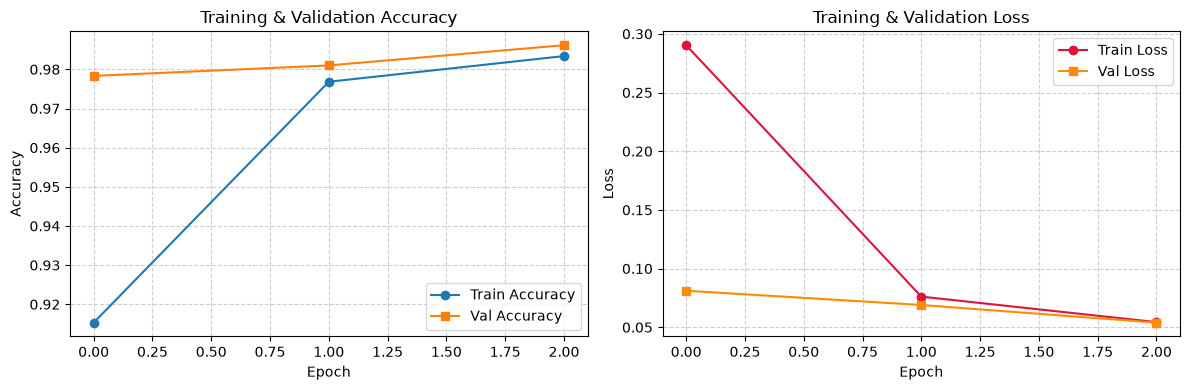

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 84ms/step

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 99ms/step


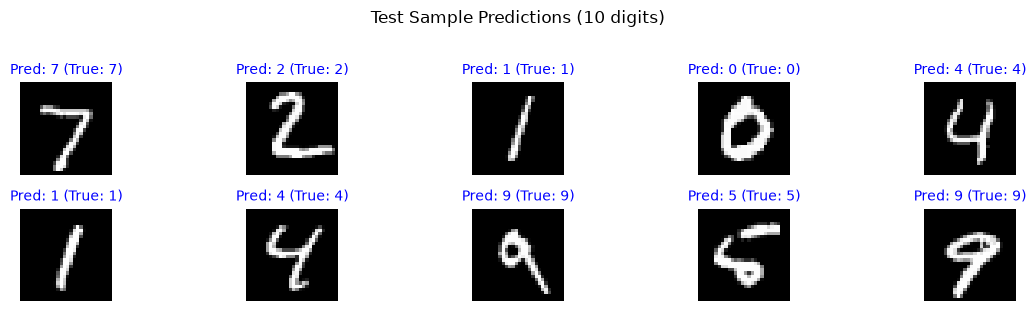

최종 테스트 손실: 0.0472
최종 테스트 정확도: 0.9843 (98.43%)


In [9]:
# [5] 학습 결과 시각화 및 테스트 예측 샘플 검증 (학생 실습 결과)
plt.figure(figsize=(12, 4))

# 1) 정확도 곡선
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Accuracy', marker='o')
plt.plot(history.history['val_accuracy'], label='Val Accuracy', marker='s')
plt.title('Training & Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)

# 2) 손실 곡선
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss', marker='o', color='crimson')
plt.plot(history.history['val_loss'], label='Val Loss', marker='s', color='darkorange')
plt.title('Training & Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

# 테스트 세트 샘플 예측 결과 시각화 (10개)
predictions = model.predict(x_test[:10])
pred_labels = np.argmax(predictions, axis=1)

plt.figure(figsize=(12, 3))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_test[i].squeeze(), cmap='gray')
    is_correct = (pred_labels[i] == y_test[i])
    color = 'blue' if is_correct else 'red'
    plt.title(f'Pred: {pred_labels[i]} (True: {y_test[i]})', color=color, fontsize=10)
    plt.axis('off')
plt.suptitle('Test Sample Predictions (10 digits)', y=1.02)
plt.tight_layout()
plt.show()

print(f"최종 테스트 손실: {test_loss:.4f}")
print(f"최종 테스트 정확도: {test_acc:.4f} ({test_acc * 100:.2f}%)")


## [6] 실습 결과 분석 및 결론 (Student Analysis & Findings)

### 1. Convolution 파라미터별 동작 분석
- **Kernel Size & Padding (2.1)**:
  - 입력 크기 `(1, 28, 28, 1)`에 대해 `kernel_size=(3, 3)` 적용 시:
    - `padding='valid'` 적용 시 경계 패딩 없이 내부만 합성곱을 수행하므로 출력 크기가 `(1, 26, 26, 1)`로 축소됨 ($28 - 3 + 1 = 26$).
    - `padding='same'` 적용 시 입력 크기를 유지하도록 0-패딩이 추가되어 출력 크기가 `(1, 28, 28, 1)`로 보존됨.
- **Stride & Dilation (2.2)**:
  - `strides=(2, 2)`: 필터가 2칸씩 건너뛰며 순회하므로 가로/세로 해상도가 절반으로 다운샘플링되어 `(1, 14, 14, 1)`이 됨.
  - `dilation_rate=(2, 2)`: 커널 요소 사이에 간격을 두어 파라미터 수 증가 없이 수용 영역(Receptive Field)을 $5 \times 5$ 크기로 확장함 (`padding='same'` 기준 출력 크기는 `(1, 28, 28, 1)` 유지).
- **Filter 개수 (2.3)**:
  - `filters=8`: 8개의 독립적인 합성곱 필터가 각각 고유한 특징(에지, 질감, 코너 등)을 감지하여 `(1, 28, 28, 8)` 형태의 다채널 피처맵을 생성함.

### 2. Pooling 기법 비교 분석 (3.0)
- **MaxPooling vs AveragePooling**:
  - `MaxPooling2D(pool_size=(2,2), strides=2)`: $2 \times 2$ 윈도우 내의 최댓값을 취하여 경계선과 두드러진 활성 신호를 보존함.
  - `AveragePooling2D(pool_size=(2,2), strides=2)`: $2 \times 2$ 윈도우 내의 평균값을 취하여 신호가 부드럽게 스무딩됨.
  - 두 방식 모두 $2 \times 2$, stride 2 조건에서 입력 `(1, 28, 28, 1)`을 `(1, 14, 14, 1)`로 축소하여 공간적 차원 감소 및 위치 이동 불변성(Translation Invariance)을 부여함.

### 3. CNN 모델 학습 및 평가 (4.0 & 5.0)
- **모델 구조**:
  - `Conv2D(32, (3,3), relu)` -> `MaxPooling2D((2,2))` -> `Conv2D(64, (3,3), relu)` -> `AveragePooling2D((2,2))` -> `Flatten` -> `Dense(64, relu)` -> `Dense(10, softmax)`
  - 총 파라미터 수: 121,930개 (약 476.3 KB)
- **실측 학습 진행 경과 (Cell 14 Programmatic Output)**:
  - Epoch 1: accuracy `0.9153`, loss `0.2903`, val_accuracy `0.9783`, val_loss `0.0811`
  - Epoch 2: accuracy `0.9768`, loss `0.0761`, val_accuracy `0.9810`, val_loss `0.0690`
  - Epoch 3: accuracy `0.9834`, loss `0.0544`, val_accuracy `0.9862`, val_loss `0.0540`
- **최종 테스트 세트 (10,000장) 평가**:
  - **테스트 손실(Test Loss)**: `0.0472`
  - **테스트 정확도(Test Accuracy)**: `98.43%` (`0.9843000173568726`)
- **실행 환경 및 셀 투명성 공시**:
  - 교수자 원본 셀 0~14를 100% 보존하였으며, 빈 코드 셀이었던 Cell 15에 평가/시각화 코드를 작성하고 Cell 16에 본 고찰을 추가함.
  - OS: macOS (Apple Silicon 10-core, 16 GB unified memory), Python 3.12.14, TensorFlow 2.21.0, Keras 3.15.1.
  - 커널스펙은 범용 제출 호환성을 위해 `python3`/`icp2026` 메타데이터를 유지하며 격리 가상환경 `lms-tg11308`에서 전 셀 실행을 완료함.
